# Instant Insanity on a quantum computer: a 3-qubits-per-cube QAOA

**Qiskit Fall Fest CT 2026 · qBraid challenge.** Levels reached: **warm-up, core and bonus (N = 4 to 8 cubes).**

The story in one paragraph. Each cube has only **6 legal ways** to sit in the tower once we ignore which way round each face pair points:
pick one opposite-face pair for front/back and a different one for left/right. Six things fit in **3 qubits**, so N cubes need **3N qubits**
(12 for the four-cube puzzle, instead of the 24 of the starter's one-hot encoding). We write the puzzle's rules as an energy
(a Hamiltonian made only of Z operators), start the qubits in an equal mix of the legal choices, and run **constrained QAOA**:
a cost layer that rewards towers that obey the rules, and a mixer that only ever swaps legal choices for legal choices.
Before running anything quantum we check the model classically against brute force, and we check every tower the circuit returns.

Sections
1. The puzzle and the classical brute force
2. Warm-up: the starter's front/back QAOA, re-run
3. The compact encoding and its Hamiltonian
4. **Classical checks** (model = brute force, simulator = Qiskit, decoder = known answer)
5. Core: tuning QAOA and running it on SV1
6. Bonus: N cubes and N colours, N = 5 to 8
7. What we learned, honestly

In [1]:
import importlib.util
import subprocess
import sys

# install only what is missing; upgrading an already-imported package can break it
NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15",
          "qbraid": "qbraid[qiskit]>=0.12", "matplotlib": "matplotlib",
          "networkx": "networkx", "scipy": "scipy", "pylatexenc": "pylatexenc"}
missing = [spec for mod, spec in NEEDED.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: nothing, everything was already here


In [2]:
import itertools
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import qiskit

from resources.helpers import SEED          # SEED = 7, used for every random step below
from src.insanity import (CHOICES, BONUS_SEEDS, ValidSpaceQAOA, bitstring_to_codes,
                          classical_cost, codes_to_bitstring, compact_hamiltonian,
                          cost_layer, cost_table, count_answers, is_solved_key,
                          make_puzzle, mixer_cube, orientations, prep_cube,
                          qaoa_circuit, sample_counts, solves, tower_of, tune,
                          two_qubit_gates_and_depth)

os.makedirs("results", exist_ok=True)
print("qiskit", qiskit.__version__, "| SEED =", SEED)

qiskit 2.6.0 | SEED = 7


## 1. The puzzle and the classical brute force

A cube is three **opposite-face pairs**; `["GR", "BR", "GY"]` means green is opposite red, blue opposite red, green opposite yellow.
A tower is solved when each of the four sides shows every colour exactly once. `orientations` and `solves` are the starter's functions
(we moved them into `src/insanity.py` unchanged).

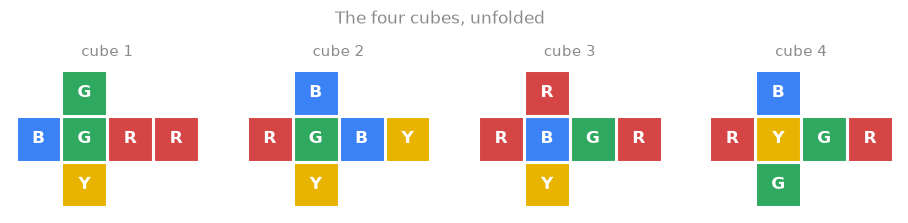

In [3]:
from resources.helpers import draw_nets

COLOURS = "RGBY"
CUBES = [
    ["GR", "BR", "GY"],   # cube 1
    ["GY", "RB", "BY"],   # cube 2
    ["BR", "RG", "RY"],   # cube 3
    ["YR", "RG", "BG"],   # cube 4
]
draw_nets(CUBES)

In [4]:
start = time.perf_counter()
winners = [t for t in itertools.product(*[orientations(c) for c in CUBES]) if solves(t)]
BRUTE_SECONDS = time.perf_counter() - start
print(f"brute force: checked {24 ** 4:,} towers in {BRUTE_SECONDS:.2f} s, found {len(winners)} solved ones")

brute force: checked 331,776 towers in 0.14 s, found 8 solved ones


**Graph view.** One node per colour, one edge per opposite pair. The front/back picks (one pair per cube) must touch every colour exactly twice
(a **2-factor**), and so must the left/right picks, with each cube using two *different* pairs. Then the 2-factor's cycles tell us which way round to put each pair.
So the puzzle only asks for one ordered pair of pair-indices per cube: 6 choices per cube, `6^4 = 1296` cases.

In [5]:
def degrees(cubes, picks):
    # How many picked lines touch each colour (starter)
    count = dict.fromkeys(COLOURS, 0)
    for cube, p in zip(cubes, picks):
        for colour in cube[p]:
            count[colour] += 1
    return count


def is_two_factor(cubes, picks):
    return all(d == 2 for d in degrees(cubes, picks).values())


front_back = [picks for picks in itertools.product(range(3), repeat=len(CUBES))
              if is_two_factor(CUBES, picks)]
graph_cases = [ch for ch in itertools.product(CHOICES, repeat=4)
               if is_two_factor(CUBES, [a for a, _ in ch]) and is_two_factor(CUBES, [b for _, b in ch])]
print(f"{len(front_back)} of 81 front/back picks are 2-factors")
print(f"{len(graph_cases)} of 1296 graph-level cases solve the puzzle: {graph_cases}")

4 of 81 front/back picks are 2-factors
2 of 1296 graph-level cases solve the puzzle: [((1, 2), (0, 2), (2, 0), (2, 1)), ((2, 1), (2, 0), (0, 2), (1, 2))]


## 2. Warm-up: the starter's front/back QAOA, re-run

The starter solves the **front/back half** only: 12 qubits, one-hot (qubit `3c + p` = "cube c puts pair p on front/back"), a W-state start
and an XY mixer that keeps exactly one qubit per cube on. We re-run it as given (p = 1 grid, then COBYLA at p = 2) so the warm-up level is
on record, and send the tuned circuit to SV1. The code is the starter's; only `cost_layer` comes from our module (it handles Z strings of any length, so also Z and ZZ).

In [6]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.circuit.library import RYGate, XGate, XXPlusYYGate
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.optimize import minimize

from resources.helpers import diagonal, solution_strings


def front_back_hamiltonian(cubes, lam=0):
    # Degree rule on the x variables only (starter)
    n = 3 * len(cubes)
    one = SparsePauliOp("I" * n)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)
    H = 0 * one
    for k in COLOURS:
        d = -2 * one
        for c, cube in enumerate(cubes):
            for p in range(3):
                d += cube[p].count(k) * var(3 * c + p)
        H += d @ d
    for c in range(len(cubes)):
        pick = sum((var(3 * c + p) for p in range(3)), -1 * one)
        H += lam * (pick @ pick)
    return H.simplify()


def w_state(qc, a, b, c):
    qc.ry(2 * np.arcsin(1 / np.sqrt(3)), a)
    qc.append(RYGate(np.pi / 2).control(1, ctrl_state=0), [a, b])
    qc.append(XGate().control(2, ctrl_state="00"), [a, b, c])


def xy_mixer(qc, beta, cubes):
    for c in range(len(cubes)):
        q = [3 * c, 3 * c + 1, 3 * c + 2]
        for i, j in ((0, 1), (0, 2), (1, 2)):
            qc.append(XXPlusYYGate(2 * beta), [q[i], q[j]])


def constrained_qaoa(H, gammas, betas, cubes=CUBES):
    qc = QuantumCircuit(3 * len(cubes))
    for c in range(len(cubes)):
        w_state(qc, 3 * c, 3 * c + 1, 3 * c + 2)
    for g, b in zip(gammas, betas):
        cost_layer(qc, H, g)
        xy_mixer(qc, b, cubes)
    return qc


H_fb = front_back_hamiltonian(CUBES)
GOOD = solution_strings(front_back)
fb_costs, fb_wins = diagonal(H_fb), [int(s, 2) for s in GOOD]
gamma, beta = Parameter("γ"), Parameter("β")
template = constrained_qaoa(H_fb, [gamma], [beta])
grid = np.linspace(0, np.pi, 41)
best = min(((Statevector(template.assign_parameters({gamma: g, beta: b})).probabilities() @ fb_costs, g, b)
            for g in grid for b in grid))
g1, b1 = best[1], best[2]
res = minimize(lambda a: Statevector(constrained_qaoa(H_fb, a[:2], a[2:])).probabilities() @ fb_costs,
               [g1, g1, b1, b1], method="COBYLA", options={"maxiter": 200})
WARM_ANGLES = res.x
warm_probs = Statevector(constrained_qaoa(H_fb, WARM_ANGLES[:2], WARM_ANGLES[2:])).probabilities()
WARM_EXACT = warm_probs[fb_wins].sum()
print(f"warm-up p=2: P(good front/back pick) = {WARM_EXACT:.1%}  (random valid pick {4/81:.1%})")

warm-up p=2: P(good front/back pick) = 28.4%  (random valid pick 4.9%)


### Sending circuits to qBraid

`submit_job` is the piece the starter leaves for the team. It connects to the SV1 simulator through qBraid, sends the circuit and returns the counts.
Every job ID is printed and saved to `results/jobs.json`. Without qBraid credentials (for example on a laptop) it says so and returns `None`;
`run_on_qbraid` (the starter's) then runs the same prepared circuit on the local Aer simulator instead. **No API key is in this notebook:**
in qBraid Lab, `QbraidProvider()` finds the account's credentials by itself.

In [7]:
from qiskit_aer import AerSimulator

from resources.helpers import prepare, strip_marker

SV1 = "aws:aws:sim:sv1"     # Amazon Braket's state-vector simulator, reached through qBraid
JOBS = []                   # every job we submit: label, job id, shots
_DEVICE = []                # the connected device, cached so we connect once


def get_sv1():
    # Connect to SV1 once. Returns None when there are no qBraid credentials.
    if not _DEVICE:
        try:
            from qbraid.runtime import QbraidProvider
            provider = QbraidProvider()                 # picks up the qBraid Lab credentials
            device = provider.get_device(SV1)           # the device object for SV1
            print("connected to", device.id, "| status:", device.status().name)
            _DEVICE.append(device)
        except Exception as err:                        # no credentials / no network
            print(f"No connection to qBraid ({type(err).__name__}); using local simulation.")
            _DEVICE.append(None)
    return _DEVICE[0]


def submit_job(qc, shots, label=""):
    # Run the prepared circuit qc on SV1 and return its counts, or None without qBraid.
    device = get_sv1()
    if device is None:
        return None
    job = device.run(qc, shots=shots)                   # send the job; returns at once
    print(f"submitted {label}: job id {job.id}")        # this id goes in the README table
    JOBS.append({"label": label, "job_id": job.id, "shots": shots, "device": SV1})
    with open("results/jobs.json", "w") as fh:          # save after every job, in case of a crash
        json.dump(JOBS, fh, indent=1)
    return job.result().data.get_counts()               # waits for the job, then reads the counts


def run_on_qbraid(circuit, shots=1000, label=""):
    # Starter's wrapper: add the marker qubit, transpile, submit, fall back to Aer.
    # Returns (counts in Qiskit order, device used, job id or None).
    qc = prepare(circuit)
    raw = submit_job(qc, shots, label)
    if raw is None:
        raw = AerSimulator(seed_simulator=SEED).run(qc, shots=shots).result().get_counts()
        return strip_marker(raw), "local Aer (SV1 pending)", None
    return strip_marker(raw), SV1, JOBS[-1]["job_id"]

In [8]:
ROWS = []   # one row of the README results table per experiment


def pct(x):
    # a probability as a percentage with 2 significant digits, e.g. 0.00043%
    return f"{100 * x:.2g}%"


def add_row(n, encoding, device, qubits, cx, depth, shots, p_correct, baseline, job):
    ROWS.append(dict(n=n, encoding=encoding, device=device, qubits=qubits, cx=cx, depth=depth,
                     shots=shots, p=p_correct, baseline=baseline, job=job or "TODO: run in qBraid Lab"))


warm_qc = constrained_qaoa(H_fb, WARM_ANGLES[:2], WARM_ANGLES[2:])
counts, device, job = run_on_qbraid(warm_qc, shots=1000, label="warm-up front/back p=2")
good = sum(counts.get(s, 0) for s in GOOD)
cx, depth = two_qubit_gates_and_depth(warm_qc)
print(f"{good} of 1000 shots are good front/back picks ({good/1000:.1%}); exact value {WARM_EXACT:.1%}")
add_row("4 (front/back only, warm-up)", "one-hot 3/cube, W-state + XY mixer, p=2", device, 12, cx, depth,
        1000, good / 1000, f"{4/4096:.3%} (bitstring) / {4/81:.1%} (one-hot)", job)

connected to aws:aws:sim:sv1 | status: ONLINE


submitted warm-up front/back p=2: job id aws:aws:sim:sv1-60f2-qjob-6ad384c338127b44c71b9a46


306 of 1000 shots are good front/back picks (30.6%); exact value 28.4%


## 3. The compact encoding and its Hamiltonian

**Encoding.** Cube `c` stores one number `k` from 0 to 5 in its three qubits `3c, 3c+1, 3c+2` (qubit `3c` is the lowest bit).
`k` names a choice (front/back pair, left/right pair):

| code k | 0 | 1 | 2 | 3 | 4 | 5 | 6, 7 |
|---|---|---|---|---|---|---|---|
| (front/back, left/right) | (0,1) | (0,2) | (1,0) | (1,2) | (2,0) | (2,1) | unused |

So "use the same pair twice" cannot even be written down, and "exactly one pick per cube" holds automatically. The only rules left are the
**degree rules**: on front/back and on left/right, every colour must be touched exactly twice.

**Cost.** `C = Σ_sides Σ_colours (d − 2)²`, where `d` is how many chosen pairs touch that colour on that side. `C = 0` exactly for a solved tower.

**Hamiltonian.** The projector "cube c holds code k" is `|k⟩⟨k| = Π_bits (1 ± Z)/2`, a sum of Z strings on 3 qubits. A colour's degree `d` is a sum
of these projectors, and `(d − 2)²` multiplies two of them, so terms touch at most 6 qubits (two cubes). We build `H` from the puzzle's structure, not by enumerating answers.

**Codes 6 and 7** never appear: the circuit starts in the 6 valid codes and its mixer only mixes valid codes, so we need **no penalty term** and no λ to tune.

**Bit order.** In a Qiskit counts key, qubit 0 is the **rightmost** character. So cube 1's code is the last three characters, read right to left as bits 0, 1, 2.

In [9]:
KNOWN = [list(map(int, k)) for k in np.argwhere(cost_table(CUBES) == 0)]   # the two zero-cost code tuples
key = codes_to_bitstring(KNOWN[0])
print("a known answer, codes per cube:", KNOWN[0], "-> choices", [CHOICES[k] for k in KNOWN[0]])
print("its Qiskit key:", key, " (cube 4 | cube 3 | cube 2 | cube 1, each 3 bits, highest bit first)")
print("decoded back  :", bitstring_to_codes(key))
assert bitstring_to_codes(key) == KNOWN[0]
assert key[-3:] == format(KNOWN[0][0], "03b"), "cube 1 must be the rightmost 3 characters"

H = compact_hamiltonian(CUBES)
print(f"\ncompact H: {H.num_qubits} qubits, {len(H)} Pauli terms, "
      f"longest Z string {max(l.count('Z') for l in H.paulis.to_labels())} qubits")

a known answer, codes per cube: [3, 1, 4, 5] -> choices [(1, 2), (0, 2), (2, 0), (2, 1)]
its Qiskit key: 101100001011  (cube 4 | cube 3 | cube 2 | cube 1, each 3 bits, highest bit first)
decoded back  : [3, 1, 4, 5]

compact H: 12 qubits, 164 Pauli terms, longest Z string 6 qubits


## 4. Classical checks

Low energy is not proof, so we check the model and the tools before trusting any quantum output. Each check raises an error if it fails.

In [10]:
valid = list(itertools.product(range(6), repeat=4))          # all 1296 valid code assignments
D = diagonal(H)                                                # H on all 4096 bitstrings
table = cost_table(CUBES)

# (1) H equals the classical cost on every valid state, and cost_table equals the slow loop
gap = max(abs(D[int(codes_to_bitstring(v), 2)] - classical_cost(CUBES, v)) for v in valid)
assert gap < 1e-9 and all(table[v] == classical_cost(CUBES, v) for v in valid)
print(f"(1) H vs classical cost on all 1296 valid states: largest gap {gap:.1e}")

# (2) the zero-energy states are exactly the brute-force answers, and each builds a solved tower
zeros = [v for v in valid if table[v] == 0]
assert len(zeros) == 2 == count_answers(CUBES) == len(graph_cases)
assert all(solves(tower_of(CUBES, list(v))) for v in zeros)
assert sorted(tuple(CHOICES[k] for k in v) for v in zeros) == sorted(graph_cases)
lowest_wrong = min(table[v] for v in valid if table[v] > 0)
print(f"(2) {len(zeros)} zero-cost states = count_answers = graph method; both pass solves(); "
      f"no ties: lowest wrong cost is {lowest_wrong}")


# (3) independent cross-check with the starter's 24-qubit QUBO cost
def starter_cost(cubes, x, y, LAMBDA=2, MU=2):
    total = 0
    for c in range(len(cubes)):
        total += LAMBDA * ((sum(x[c]) - 1) ** 2 + (sum(y[c]) - 1) ** 2)
        total += MU * sum(x[c][p] * y[c][p] for p in range(3))
    for picks in (x, y):
        for k in COLOURS:
            d = sum(cubes[c][p].count(k) * picks[c][p] for c in range(len(cubes)) for p in range(3))
            total += (d - 2) ** 2
    return total


one_hot = lambda p: [int(i == p) for i in range(3)]
starter_zero = [v for v in valid
                if starter_cost(CUBES, [one_hot(CHOICES[k][0]) for k in v], [one_hot(CHOICES[k][1]) for k in v]) == 0]
assert starter_zero == zeros
print("(3) the starter's QUBO cost is zero on exactly the same 2 states")

# (4) the start state is an equal mix of the 6 valid codes, with nothing on codes 6 and 7
qc = QuantumCircuit(3)
prep_cube(qc, 0)
probs = Statevector(qc).probabilities()
assert np.allclose(probs[:6], 1 / 6) and np.allclose(probs[6:], 0)
print("(4) prep_cube gives probability", np.round(probs, 4))

# (5) the full circuit, at random angles, never leaves the valid codes, and
# (6) our fast 6^N simulator matches Qiskit's Statevector of the real circuit
rng = np.random.default_rng(SEED)
g, b = rng.uniform(0, np.pi, 3), rng.uniform(0, 2 * np.pi, 3)
probs = Statevector(qaoa_circuit(CUBES, H, g, b)).probabilities()
idx = [int(codes_to_bitstring(v), 2) for v in valid]
leak = 1 - probs[idx].sum()
fast = np.abs(ValidSpaceQAOA(CUBES).state(g, b)) ** 2
sim_gap = max(abs(probs[i] - fast[v]) for i, v in zip(idx, valid))
assert leak < 1e-9 and sim_gap < 1e-9
print(f"(5) probability outside the valid codes at random p=3 angles: {leak:.1e}")
print(f"(6) fast simulator vs Statevector of the circuit: largest gap {sim_gap:.1e}")
print("\nall classical checks passed")

(1) H vs classical cost on all 1296 valid states: largest gap 0.0e+00
(2) 2 zero-cost states = count_answers = graph method; both pass solves(); no ties: lowest wrong cost is 2
(3) the starter's QUBO cost is zero on exactly the same 2 states
(4) prep_cube gives probability [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667 0.     0.    ]
(5) probability outside the valid codes at random p=3 angles: 2.1e-15
(6) fast simulator vs Statevector of the circuit: largest gap 2.9e-17

all classical checks passed


**What the checks say.** (1) and (3) show the energy we built is the right puzzle; (2) shows the lowest energy is the answer and nothing wrong ties with it;
(4) and (5) show the circuit really stays in the 6-codes-per-cube space, which is why no penalty is needed; (6) lets us tune angles with a fast simulator that
we know matches the circuit. On top of all this, **every shot we report below is decoded and checked with `solves`** (`is_solved_key`).

## 5. Core: tuning QAOA and running it on SV1

**The circuit.** Start: each cube in an equal mix of its 6 codes (`prep_cube`, below). Then `p` rounds of
* **cost layer** `exp(−iγH)`: each Z string becomes a CNOT ladder, one RZ, and the ladder undone;
* **mixer** `exp(−iβ|u⟩⟨u|)` on each cube, where `|u⟩` is that cube's equal mix: undo the prep, put a phase on `|000⟩`, redo the prep.
  It is the "complete graph" mixer over the 6 codes, so it can turn any legal choice into any other.

Below: one cube's start and one mixer step.

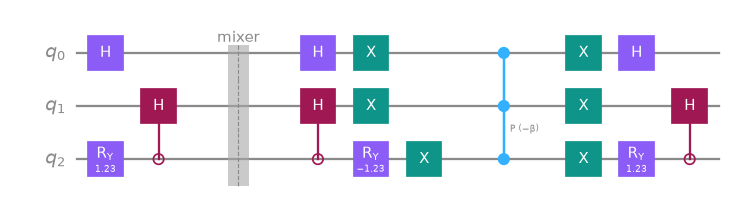

In [11]:
from resources.helpers import CIRCUIT, show

one = QuantumCircuit(3)
prep_cube(one, 0)
one.barrier(label="mixer")
mixer_cube(one, 0, Parameter("β"))
fig = one.draw("mpl", style=CIRCUIT, fold=-1, scale=0.75)
fig.savefig("results/circuit_one_cube.png", dpi=160, bbox_inches="tight", transparent=False, facecolor="white")
show(fig)

**Tuning.** We pick the angles by minimising the **average cost** of the output (what an experiment could measure without knowing the answer); we never use
the solutions to tune. We grow the circuit one layer at a time and start each depth from the previous angles stretched to one more layer (INTERP).
This runs on the exact 1296-amplitude simulator, about 15 seconds in total.

  p= 1: average cost  4.621, P(correct)   1.10%
  p= 2: average cost  3.516, P(correct)   2.74%


  p= 3: average cost  3.040, P(correct)   4.77%


  p= 4: average cost  2.646, P(correct)   8.81%


  p= 5: average cost  2.316, P(correct)  14.18%


  p= 6: average cost  2.074, P(correct)  21.13%


...

  p= 8: average cost  1.582, P(correct)  41.79%


  p= 9: average cost  1.335, P(correct)  50.15%


  p=10: average cost  1.139, P(correct)  57.93%


  p=11: average cost  0.956, P(correct)  65.96%


  p=12: average cost  0.769, P(correct)  72.89%
tuned p = 1..12 in 4 s


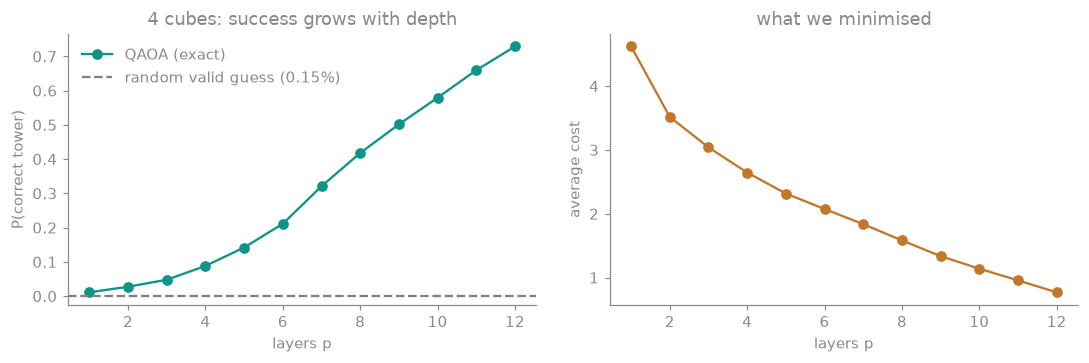

In [12]:
sim4 = ValidSpaceQAOA(CUBES)
start = time.perf_counter()
TUNED4 = tune(sim4, p_max=12, maxiter=500)
print(f"tuned p = 1..12 in {time.perf_counter() - start:.0f} s")

ps = [r["p"] for r in TUNED4]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ps, [r["P"] for r in TUNED4], "o-", color="#0E9488", label="QAOA (exact)")
ax[0].axhline(2 / 1296, color="grey", ls="--", label="random valid guess (0.15%)")
ax[0].set(xlabel="layers p", ylabel="P(correct tower)", title="4 cubes: success grows with depth")
ax[0].legend(frameon=False)
ax[1].plot(ps, [r["E"] for r in TUNED4], "o-", color="#C2772A")
ax[1].set(xlabel="layers p", ylabel="average cost", title="what we minimised")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("results/core_p_sweep.png", dpi=160, facecolor="white")
plt.show()

**Runs.** Four circuits, p = 1, 4, 8 and 12, 1000 shots each. Every shot is decoded and checked with `solves`.
The random-guess baseline is the chance a uniform random 12-bit string is a solved tower, `2/4096 = 0.049%`
(or `2/1296 = 0.15%` if we only guess valid codes).

In [13]:
CORE = {}
for p in (1, 4, 8, 12):
    r = TUNED4[p - 1]
    qc = qaoa_circuit(CUBES, H, r["g"], r["b"])
    cx, depth = two_qubit_gates_and_depth(qc)
    counts, device, job = run_on_qbraid(qc, shots=1000, label=f"core N=4 p={p}")
    hits = sum(n for k, n in counts.items() if is_solved_key(CUBES, k))     # check EVERY shot
    invalid = sum(n for k, n in counts.items() if bitstring_to_codes(k) is None)
    CORE[p] = counts
    print(f"p={p:2d}: {cx:5d} CX, depth {depth:5d} | {hits:4d}/1000 solved towers ({hits/10:.1f}%), "
          f"exact {r['P']:.1%} | invalid-code shots: {invalid}")
    add_row(4, f"compact 3 qubits/cube, constrained QAOA p={p}", device, 12, cx, depth, 1000,
            hits / 1000, "0.049% (bitstring) / 0.15% (valid)", job)

submitted core N=4 p=1: job id aws:aws:sim:sv1-60f2-qjob-6ad384d338127b44c71b9a53


p= 1:   550 CX, depth   522 |   17/1000 solved towers (1.7%), exact 1.1% | invalid-code shots: 0


submitted core N=4 p=4: job id aws:aws:sim:sv1-60f2-qjob-6ad3850138127b44c71b9a5a


p= 4:  2188 CX, depth  2040 |   87/1000 solved towers (8.7%), exact 8.8% | invalid-code shots: 0


submitted core N=4 p=8: job id aws:aws:sim:sv1-60f2-qjob-6ad3853638127b44c71b9a74


p= 8:  4372 CX, depth  4064 |  421/1000 solved towers (42.1%), exact 41.8% | invalid-code shots: 0


submitted core N=4 p=12: job id aws:aws:sim:sv1-60f2-qjob-6ad3857838127b44c71b9a82


p=12:  6556 CX, depth  6088 |  733/1000 solved towers (73.3%), exact 72.9% | invalid-code shots: 0


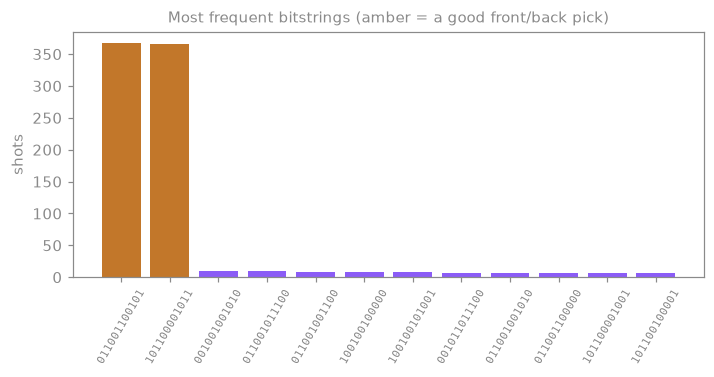

most frequent solved key: 011001100101 -> codes [5, 4, 1, 3]
tower (front, left, back, right) per cube: [('G', 'B', 'Y', 'R'), ('Y', 'Y', 'B', 'G'), ('B', 'R', 'R', 'Y'), ('R', 'G', 'G', 'B')] | solves: True


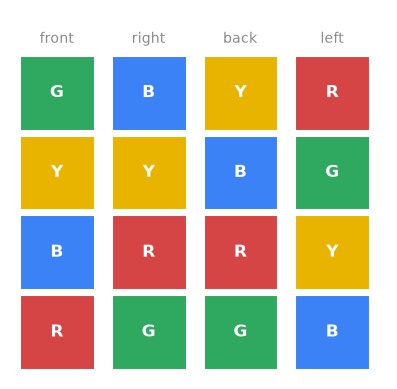

In [14]:
from resources.helpers import draw_tower, plot_top_counts

SOLVED = [codes_to_bitstring(v) for v in zeros]
plot_top_counts(CORE[12], SOLVED)
top = max((k for k in CORE[12] if is_solved_key(CUBES, k)), key=CORE[12].get)
print("most frequent solved key:", top, "-> codes", bitstring_to_codes(top))
tower = tower_of(CUBES, bitstring_to_codes(top))
print("tower (front, left, back, right) per cube:", tower, "| solves:", solves(tower))
draw_tower(tower)

## 6. Bonus: N cubes and N colours

We use the starter's `make_puzzle` with the seeds it lists, `{5: 16, 6: 86, 7: 68, 8: 4}`; each has exactly one tower (2 graph-level cases),
which we confirm with `count_answers`. Nothing in the method is specific to 4 cubes: 3N qubits, the same Hamiltonian builder, the same circuit.

In [15]:
PUZZLES = {4: CUBES, **{n: make_puzzle(n, s) for n, s in BONUS_SEEDS.items()}}
HAMS, SIMS = {}, {}
for n, cubes in PUZZLES.items():
    start = time.perf_counter()
    answers = count_answers(cubes)
    t_count = time.perf_counter() - start
    HAMS[n], SIMS[n] = compact_hamiltonian(cubes), ValidSpaceQAOA(cubes)
    zero_codes = [list(map(int, v)) for v in np.argwhere(SIMS[n].costs == 0)]
    assert answers == len(zero_codes) == 2
    assert all(solves(tower_of(cubes, v)) for v in zero_codes)
    print(f"N={n}: {6**n:>9,} cases, count_answers = {answers} ({t_count:5.1f} s); zero-cost states = "
          f"{len(zero_codes)}, both pass solves(); H has {len(HAMS[n])} terms")

N=4:     1,296 cases, count_answers = 2 (  0.0 s); zero-cost states = 2, both pass solves(); H has 164 terms
N=5:     7,776 cases, count_answers = 2 (  0.0 s); zero-cost states = 2, both pass solves(); H has 276 terms
N=6:    46,656 cases, count_answers = 2 (  0.0 s); zero-cost states = 2, both pass solves(); H has 430 terms


N=7:   279,936 cases, count_answers = 2 (  0.3 s); zero-cost states = 2, both pass solves(); H has 541 terms


N=8: 1,679,616 cases, count_answers = 2 (  2.2 s); zero-cost states = 2, both pass solves(); H has 684 terms


In [16]:
def h_on_codes(H, code_rows):
    # Value of a Z-only Hamiltonian on many code assignments at once
    n = H.num_qubits
    bits = np.array([[(k >> i) & 1 for k in row for i in range(3)] for row in code_rows])   # bits[:, q]
    zmask = np.array([[op == "Z" for op in reversed(lbl)] for lbl in H.paulis.to_labels()])  # terms x qubits
    signs = 1 - 2 * ((bits.astype(int) @ zmask.T.astype(int)) % 2)
    return signs @ H.coeffs.real


rng = np.random.default_rng(SEED)
for n, cubes in PUZZLES.items():
    if n <= 6:
        rows = list(itertools.product(range(6), repeat=n))                    # every valid state
        how = "all"
    else:
        rows = [tuple(r) for r in rng.integers(0, 6, (3000, n))]              # a seeded random sample
        rows += [tuple(map(int, v)) for v in np.argwhere(SIMS[n].costs == 0)] # plus the two answers
        how = "sample of"
    hv = np.concatenate([h_on_codes(HAMS[n], rows[i:i + 20000]) for i in range(0, len(rows), 20000)])
    cv = np.array([SIMS[n].costs[r] for r in rows])
    gap = np.abs(hv - cv).max()
    assert gap < 1e-8
    print(f"N={n}: H vs classical cost on {how} {len(rows):,} valid states: largest gap {gap:.1e}")

N=4: H vs classical cost on all 1,296 valid states: largest gap 0.0e+00
N=5: H vs classical cost on all 7,776 valid states: largest gap 0.0e+00


N=6: H vs classical cost on all 46,656 valid states: largest gap 0.0e+00
N=7: H vs classical cost on sample of 3,002 valid states: largest gap 0.0e+00
N=8: H vs classical cost on sample of 3,002 valid states: largest gap 0.0e+00


**Angles for N = 5 to 8.** Tuning at N = 8 means thousands of evaluations on 1.7 million amplitudes, which takes about an hour, too long for a
notebook that should run top to bottom in a few minutes. So `src/tune_angles.py` ran the **same `tune` function** offline (layer growth, INTERP, plus the angles
from the next smaller N as a second starting point, average-cost objective) and saved `results/angles.json`. Set `RETUNE = True` to redo it here.
We do not just trust the file: the cell below **recomputes** each average cost and P(correct) from the saved angles.

In [17]:
RETUNE = False
P_BONUS = 10        # same depth budget for every N, so the trend with N is fair

if RETUNE:
    from src.tune_angles import main as retune
    retune()
ANGLES = {int(n): v for n, v in json.load(open("results/angles.json")).items()}
for n in PUZZLES:
    r = ANGLES[n][P_BONUS - 1]
    e, s = SIMS[n].stats(r["g"], r["b"])
    assert abs(s - r["P"]) < 1e-9
    print(f"N={n}: p={P_BONUS}: average cost {e:.3f}, P(correct) {s:.3%} "
          f"(random valid {2/6**n:.5%}, ratio x{s/(2/6**n):,.0f})")

N=4: p=10: average cost 1.139, P(correct) 57.880% (random valid 0.15432%, ratio x375)
N=5: p=10: average cost 2.076, P(correct) 9.109% (random valid 0.02572%, ratio x354)
N=6: p=10: average cost 3.019, P(correct) 9.456% (random valid 0.00429%, ratio x2,206)
N=7: p=10: average cost 3.668, P(correct) 3.484% (random valid 0.00071%, ratio x4,877)


N=8: p=10: average cost 3.731, P(correct) 4.293% (random valid 0.00012%, ratio x36,057)


**Bonus runs.** With `BONUS_ON_QBRAID = True` every circuit goes to SV1 when qBraid is connected. Rough cost: SV1 bills 7.5 credits per minute,
and the 24-qubit, 21k-CNOT N = 8 circuit should take a few minutes (we estimate 10 to 40 credits for the whole bonus; check the jobs page).
Without qBraid, N ≤ 6 runs on local Aer; N = 7 and 8 are too slow for Aer on a laptop (N = 8 took 13 minutes), so we draw the shots from the
**exact** output distribution with a seeded generator and label those rows `exact sim (local)`. Every shot is still checked with `solves`.

In [18]:
BONUS_ON_QBRAID = True
SHOTS_BONUS = 2000
SCALE = []
for n, cubes in PUZZLES.items():
    r = ANGLES[n][P_BONUS - 1]
    qc = qaoa_circuit(cubes, HAMS[n], r["g"], r["b"])
    cx, depth = two_qubit_gates_and_depth(qc)
    device = job = None
    if BONUS_ON_QBRAID and get_sv1() is not None:
        counts, device, job = run_on_qbraid(qc, shots=SHOTS_BONUS, label=f"bonus N={n} p={P_BONUS}")
    elif n <= 6:
        counts, device, job = run_on_qbraid(qc, shots=SHOTS_BONUS)
    else:
        counts, device = sample_counts(SIMS[n], r["g"], r["b"], SHOTS_BONUS, SEED), "exact sim (local)"
    hits = sum(m for k, m in counts.items() if is_solved_key(cubes, k))
    SCALE.append(dict(n=n, qubits=3 * n, terms=len(HAMS[n]), cx=cx, depth=depth, exact=r["P"],
                      measured=hits / SHOTS_BONUS, rand_valid=2 / 6 ** n, rand_bits=2 / 8 ** n))
    print(f"N={n}: {3*n} qubits, {cx:6d} CX, depth {depth:6d} | {hits:4d}/{SHOTS_BONUS} solved "
          f"({hits/SHOTS_BONUS:.2%}), exact {r['P']:.2%} | {device}")
    add_row(n, f"compact 3 qubits/cube, constrained QAOA p={P_BONUS}", device, 3 * n, cx, depth,
            SHOTS_BONUS, hits / SHOTS_BONUS, f"{pct(2/8**n)} (bitstring) / {pct(2/6**n)} (valid)", job)

submitted bonus N=4 p=10: job id aws:aws:sim:sv1-60f2-qjob-6ad385c138127b44c71b9a96


N=4: 12 qubits,   5464 CX, depth   5076 | 1175/2000 solved (58.75%), exact 57.88% | aws:aws:sim:sv1


submitted bonus N=5 p=10: job id aws:aws:sim:sv1-60f2-qjob-6ad3860638127b44c71b9aa4


N=5: 15 qubits,   9285 CX, depth   8591 |  190/2000 solved (9.50%), exact 9.11% | aws:aws:sim:sv1


submitted bonus N=6 p=10: job id aws:aws:sim:sv1-60f2-qjob-6ad3866a38127b44c71b9aba


N=6: 18 qubits,  13446 CX, depth  12001 |  189/2000 solved (9.45%), exact 9.46% | aws:aws:sim:sv1


submitted bonus N=7 p=10: job id aws:aws:sim:sv1-60f2-qjob-6ad386e638127b44c71b9ae7


N=7: 21 qubits,  16627 CX, depth  14235 |   66/2000 solved (3.30%), exact 3.48% | aws:aws:sim:sv1


submitted bonus N=8 p=10: job id aws:aws:sim:sv1-60f2-qjob-6ad3876738127b44c71b9b23


N=8: 24 qubits,  21128 CX, depth  17443 |   66/2000 solved (3.30%), exact 4.29% | aws:aws:sim:sv1


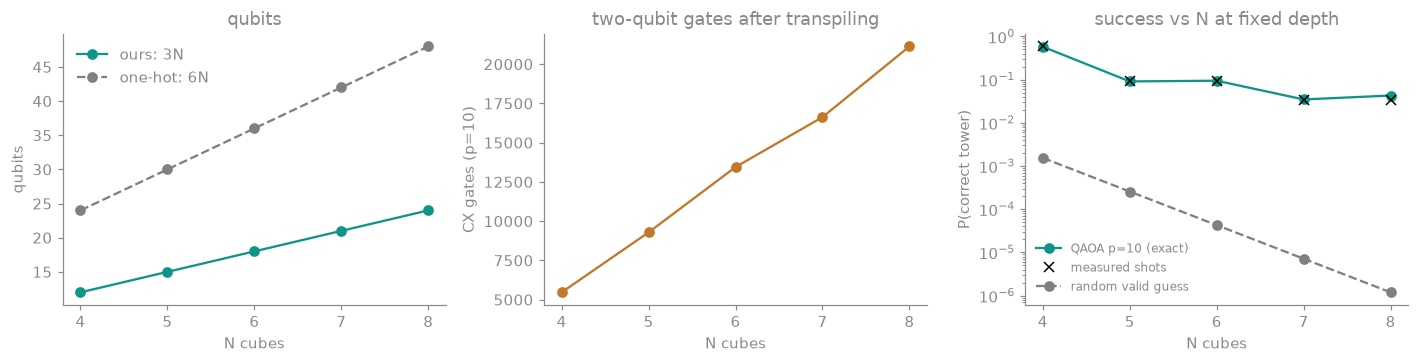

N | qubits | H terms | CX | depth | P exact | random valid | ratio
4 | 12 | 164 | 5464 | 5076 | 57.880% | 1.54e-03 | x375
5 | 15 | 276 | 9285 | 8591 | 9.109% | 2.57e-04 | x354
6 | 18 | 430 | 13446 | 12001 | 9.456% | 4.29e-05 | x2,206
7 | 21 | 541 | 16627 | 14235 | 3.484% | 7.14e-06 | x4,877
8 | 24 | 684 | 21128 | 17443 | 4.293% | 1.19e-06 | x36,057


In [19]:
ns = [s["n"] for s in SCALE]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(ns, [s["qubits"] for s in SCALE], "o-", color="#0E9488", label="ours: 3N")
ax[0].plot(ns, [6 * n for n in ns], "o--", color="grey", label="one-hot: 6N")
ax[0].set(xlabel="N cubes", ylabel="qubits", title="qubits")
ax[0].legend(frameon=False)
ax[1].plot(ns, [s["cx"] for s in SCALE], "o-", color="#C2772A")
ax[1].set(xlabel="N cubes", ylabel=f"CX gates (p={P_BONUS})", title="two-qubit gates after transpiling")
ax[2].semilogy(ns, [s["exact"] for s in SCALE], "o-", color="#0E9488", label=f"QAOA p={P_BONUS} (exact)")
ax[2].semilogy(ns, [max(s["measured"], 1e-7) for s in SCALE], "x", color="black", label="measured shots")
ax[2].semilogy(ns, [s["rand_valid"] for s in SCALE], "o--", color="grey", label="random valid guess")
ax[2].set(xlabel="N cubes", ylabel="P(correct tower)", title="success vs N at fixed depth")
ax[2].legend(frameon=False, fontsize=8)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("results/bonus_scaling.png", dpi=160, facecolor="white")
plt.show()

print("N | qubits | H terms | CX | depth | P exact | random valid | ratio")
for s in SCALE:
    print(f"{s['n']} | {s['qubits']} | {s['terms']} | {s['cx']} | {s['depth']} | {s['exact']:.3%} | "
          f"{s['rand_valid']:.2e} | x{s['exact']/s['rand_valid']:,.0f}")

In [20]:
def fmt(x):
    return f"{x:.1%}" if x >= 0.01 else f"{x:.2%}"

lines = ["| Puzzle (N cubes) | Encoding | Device | Qubits | Two-qubit gates (after transpiling) | Depth | Shots "
         "| P(correct tower) | Random-guess baseline | qBraid job ID |", "|" + "---|" * 10]
for r in ROWS:
    lines.append(f"| {r['n']} | {r['encoding']} | {r['device']} | {r['qubits']} | {r['cx']} | {r['depth']} | "
                 f"{r['shots']} | {fmt(r['p'])} | {r['baseline']} | {r['job']} |")
TABLE = "\n".join(lines)
with open("results/results.md", "w") as fh:
    fh.write(TABLE + "\n")
with open("results/jobs.json", "w") as fh:
    json.dump(JOBS, fh, indent=1)
with open("results/summary.json", "w") as fh:
    json.dump({"rows": ROWS, "scale": SCALE, "core": [dict(p=r["p"], E=r["E"], P=r["P"]) for r in TUNED4],
               "brute_seconds": BRUTE_SECONDS}, fh, indent=1)
print(TABLE)
print(f"\n{len(JOBS)} qBraid jobs recorded in results/jobs.json")

| Puzzle (N cubes) | Encoding | Device | Qubits | Two-qubit gates (after transpiling) | Depth | Shots | P(correct tower) | Random-guess baseline | qBraid job ID |
|---|---|---|---|---|---|---|---|---|---|
| 4 (front/back only, warm-up) | one-hot 3/cube, W-state + XY mixer, p=2 | aws:aws:sim:sv1 | 12 | 300 | 215 | 1000 | 30.6% | 0.098% (bitstring) / 4.9% (one-hot) | aws:aws:sim:sv1-60f2-qjob-6ad384c338127b44c71b9a46 |
| 4 | compact 3 qubits/cube, constrained QAOA p=1 | aws:aws:sim:sv1 | 12 | 550 | 522 | 1000 | 1.7% | 0.049% (bitstring) / 0.15% (valid) | aws:aws:sim:sv1-60f2-qjob-6ad384d338127b44c71b9a53 |
| 4 | compact 3 qubits/cube, constrained QAOA p=4 | aws:aws:sim:sv1 | 12 | 2188 | 2040 | 1000 | 8.7% | 0.049% (bitstring) / 0.15% (valid) | aws:aws:sim:sv1-60f2-qjob-6ad3850138127b44c71b9a5a |
| 4 | compact 3 qubits/cube, constrained QAOA p=8 | aws:aws:sim:sv1 | 12 | 4372 | 4064 | 1000 | 42.1% | 0.049% (bitstring) / 0.15% (valid) | aws:aws:sim:sv1-60f2-qjob-6ad3853638127b44c71b9a74 |
|

## 7. What we learned, honestly

* **The encoding pays off.** 3 qubits per cube (12 for the puzzle, 3N in general) instead of 6. Because the circuit can only hold legal choices, there are
  no penalty weights to tune and no shots wasted on impossible towers (we measured zero invalid-code shots).
* **QAOA does concentrate probability on the answer.** For four cubes, at p = 12 roughly three shots in four are the solved tower, against 0.15% for a random
  legal guess. The angles were tuned on the average cost only, never on the answer.
* **No speedup.** Brute force checks all 331,776 towers in well under a second, and tuning the angles needed a classical simulation of the whole state.
  This is a demonstration that the method works and is checked, not a faster solver.
* **It gets harder with N.** At a fixed depth (p = 10) success falls from about 58% (N = 4) to about 4% (N = 8; 3.3% measured on SV1), while the random baseline falls even faster
  (a factor 6 per cube); the ratio over random guessing grows with N. Two-qubit gates per layer grew from about 550 (N = 4) to about 2,100 (N = 8), close to linear in N for these puzzles
  (in the worst case the Hamiltonian has terms for every pair of cubes that share a colour, so up to N²). Keeping success constant would need more layers as N grows; we did not measure how many.
* **The cost terms are long.** Terms touch up to 6 qubits, so each needs a CNOT ladder; one layer is about 550 CNOTs at N = 4. That is fine on a simulator but too
  deep for today's hardware without fewer layers or a cleverer compilation.

**Next things to try:** a CVaR objective (optimise the best shots, not the average), smarter gate ordering in the cost layer to cancel CNOTs, angle schedules transferred
from small N to large N without retuning, Grover-style amplitude amplification with a reversible degree-counting oracle, and one shallow run on real hardware next to the SV1 run.